# Linear Regression

## Production and Electricity Usage

This example estimates monthly electricity usage at a car manufacturing plant from its monthly production value. 

The original dataset contains 12 observations, from January to December. 

Production is measured in **millions of dollars** and
electricity usage in **millions of kWh**, as shown in the original table below.

**Learning objectives:** 
* inspect and validate data; 
* visualize the relationship;
* derive an ordinary least-squares line manually; 
* fit the same model with scikit-learn; 
* interpret predictions, errors, and correlation; 
* distinguish an explanatory fit from an out-of-sample evaluation.

Run the code cells from top to bottom in Python 3, Jupyter, or Google Colab.

Required packages: `numpy`, `pandas`, `matplotlib`, `scipy`, and `scikit-learn`.
If necessary, install these in a separate setup cell using
`%pip install numpy pandas matplotlib scipy scikit-learn` and restart the kernel.


## Original data reference

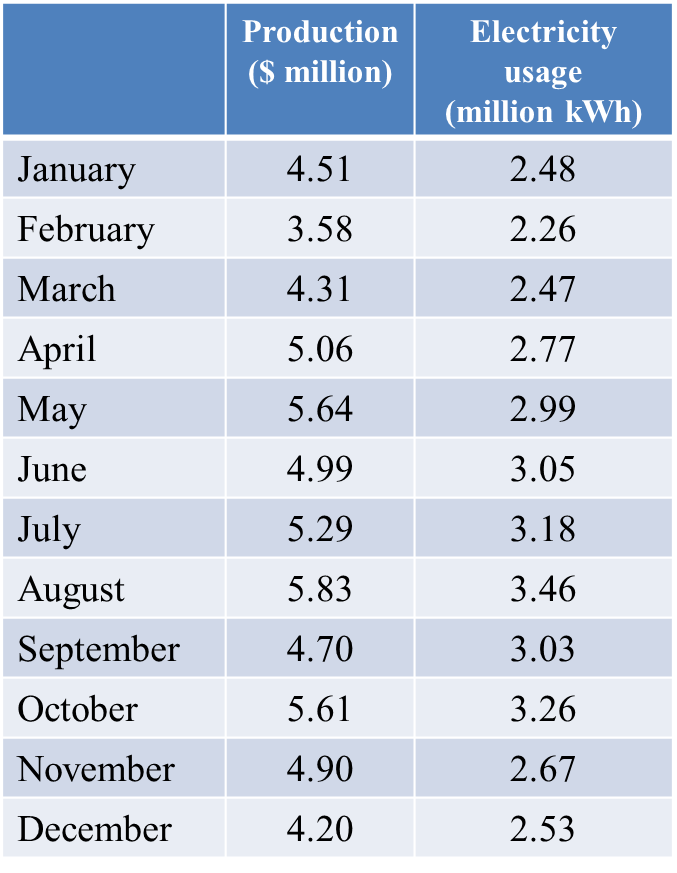


### 1. Import the required libraries

* NumPy supports numerical calculations,
* pandas holds the data,
* Matplotlib creates the figures, 
* SciPy supplies density estimates and a normal probability plot,
* scikit-learn supplies the regression model and evaluation metrics. 


In [11]:
from pathlib import Path
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True,"grid.alpha": 0.25, "font.size": 11})


### 2. Choose the data source

Set `DATA_PATH` to an existing `CarPlant.csv` file, or leave it as `None` to use the original 12 observations embedded below. 

In [12]:
DATA_PATH = None  # Example: Path("CarPlant.csv")

ORIGINAL_CSV = """Month,production,electricity
January,4.51,2.48
February,3.58,2.26
March,4.31,2.47
April,5.06,2.77
May,5.64,2.99
June,4.99,3.05
July,5.29,3.18
August,5.83,3.46
September,4.70,3.03
October,5.61,3.26
November,4.90,2.67
December,4.20,2.53
"""


### 3. Load the observations

Read either the selected CSV or the embedded original data. 

`raw_df` retains an untouched copy so that later calculations do not overwrite the source table.


In [14]:
if DATA_PATH is None:
    raw_df = pd.read_csv(StringIO(ORIGINAL_CSV))
    print("Source: original 12-month dataset embedded in this notebook.")
else:
    data_path = Path(DATA_PATH).expanduser()
    if not data_path.is_file():
        raise FileNotFoundError(f"CSV not found: {data_path}")
    raw_df = pd.read_csv(data_path)
    print(f"Source: {data_path}")
display(raw_df)

Source: original 12-month dataset embedded in this notebook.


,Month,production,electricity
0,January,4.51,2.48
1,February,3.58,2.26
2,March,4.31,2.47
3,April,5.06,2.77
4,May,5.64,2.99
5,June,4.99,3.05
6,July,5.29,3.18
7,August,5.83,3.46
8,September,4.70,3.03
9,October,5.61,3.26


### 4. Normalize column names and validate the data

Normalize capitalization and whitespace. 

Required numeric values must be finite, present, and nonnegative. 

The complete workflow requires at least six rows (three or more for training and three for testing) and variation in both variables. 

Missing or invalid values are reported instead of silently removed. 

Duplicate month labels are flagged because they may represent either data errors or multiple years.


In [15]:
df = raw_df.copy()
df.columns = df.columns.str.strip().str.lower()
if df.columns.duplicated().any():
    raise ValueError("Duplicate column names after normalization.")
required = ["month", "production", "electricity"]
missing = set(required).difference(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")
df = df[required].copy()
if df["month"].isna().any():
    raise ValueError("Month labels must not be missing.")
df["month"] = df["month"].astype(str).str.strip()
if df["month"].eq("").any():
    raise ValueError("Month labels must not be empty.")
for column in ["production", "electricity"]:
    df[column] = pd.to_numeric(df[column], errors="raise")
values = df[["production", "electricity"]].to_numpy(dtype=float)
if not np.isfinite(values).all():
    raise ValueError("Production and electricity must contain only finite, nonmissing values.")
if (values < 0).any():
    raise ValueError("Production and electricity must be nonnegative.")
if len(df) < 6 or (df[["production", "electricity"]].nunique() < 2).any():
    raise ValueError("Use at least six observations with variation in both variables.")
if df["month"].duplicated().any():
    print("Warning: repeated month labels; verify observation order and year information.")
print(f"Validated {len(df)} observations.")
display(df)

Validated 12 observations.


,month,production,electricity
0,January,4.51,2.48
1,February,3.58,2.26
2,March,4.31,2.47
3,April,5.06,2.77
4,May,5.64,2.99
5,June,4.99,3.05
6,July,5.29,3.18
7,August,5.83,3.46
8,September,4.70,3.03
9,October,5.61,3.26


### 5. Preview the first observations

`head()` shows the first five rows, which is a quick way to check the normalized column names and the data format.


In [16]:
display(df.head())

,month,production,electricity
0,January,4.51,2.48
1,February,3.58,2.26
2,March,4.31,2.47
3,April,5.06,2.77
4,May,5.64,2.99


### 6. Check the dimensions

The shape is `(number of observations, number of columns)`. 

The original data have 12 rows and three columns: one month label and two numeric variables.


In [17]:
print(f"Rows: {df.shape[0]}, columns: {df.shape[1]}")

Rows: 12, columns: 3


### 7. Summarize the numeric variables

`describe()` reports the count, mean, sample standard deviation, quartiles, minimum, and maximum. 

These summaries help check the scale and observed range of each variable.


In [18]:
display(df[["production", "electricity"]].describe())

,production,electricity
count,12.000000,12.000000
mean,4.885000,2.845833
std,0.665535,0.370686
min,3.580000,2.260000
25%,4.460000,2.517500
50%,4.945000,2.880000
75%,5.370000,3.082500
max,5.830000,3.460000


### 8. Inspect column types and completeness

`info()` lists data types and nonmissing counts. 

Production and electricity must be numeric for regression, while month is retained as a label.


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   month        12 non-null     object 
 1   production   12 non-null     float64
 2   electricity  12 non-null     float64
dtypes: float64(2), object(1)
memory usage: 420.0+ bytes


### 9. Examine the production distribution

A kernel density estimate gives a smoothed view of production values. 

With only 12 observations, its shape is sensitive to smoothing and should not be treated as evidence of a particular population distribution. 

The ticks at the bottom show the observed values.


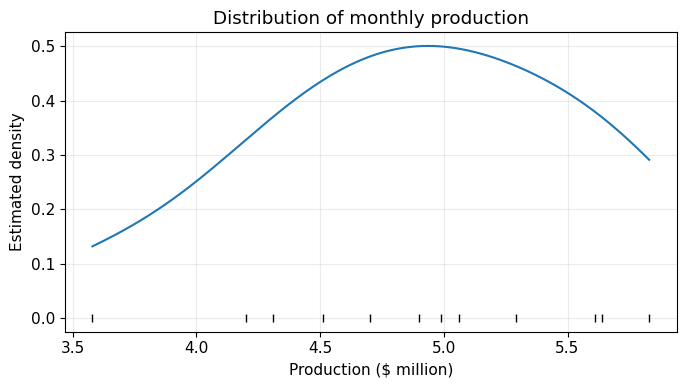

In [20]:
production = df["production"]
grid = np.linspace(production.min(), production.max(), 200)
plt.plot(grid, stats.gaussian_kde(production)(grid))
plt.plot(production, np.zeros(len(production)), "|", color="black")
plt.xlabel("Production ($ million)")
plt.ylabel("Estimated density")
plt.title("Distribution of monthly production")
plt.tight_layout()
plt.show()

### 10. Examine the electricity distribution

Repeat the density plot for electricity usage. 

Its horizontal axis uses millions of kWh; density values are not probabilities at individual points.


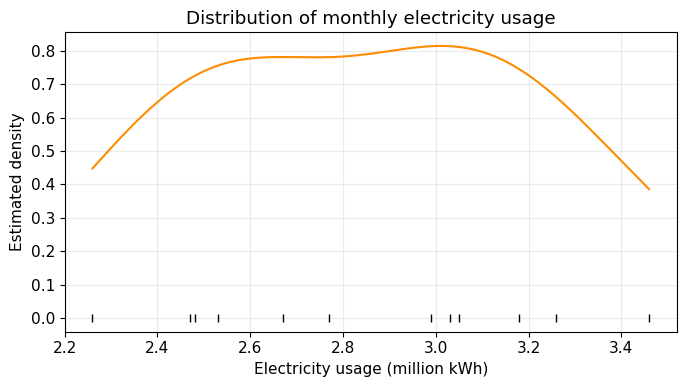

In [21]:
electricity = df["electricity"]
grid = np.linspace(electricity.min(), electricity.max(), 200)
plt.plot(grid, stats.gaussian_kde(electricity)(grid), color="darkorange")
plt.plot(electricity, np.zeros(len(electricity)), "|", color="black")
plt.xlabel("Electricity usage (million kWh)")
plt.ylabel("Estimated density")
plt.title("Distribution of monthly electricity usage")
plt.tight_layout()
plt.show()

### 11. Define the predictor and response

Select columns by name to avoid depending on their positions. 

Scikit-learn expects `X` to be two-dimensional, so double brackets create one feature column; `y` is a one-dimensional response vector. 

This notebook uses lowercase `y` consistently to avoid accidental broadcasting between incompatible array shapes.


In [22]:
X = df[["production"]].to_numpy(dtype=float)
y = df["electricity"].to_numpy(dtype=float)
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (12, 1)
y shape: (12,)


### 12. Plot production against electricity

Each point represents one month. 

A roughly straight upward pattern supports examining a positive linear association, although a scatter plot cannot establish causality.


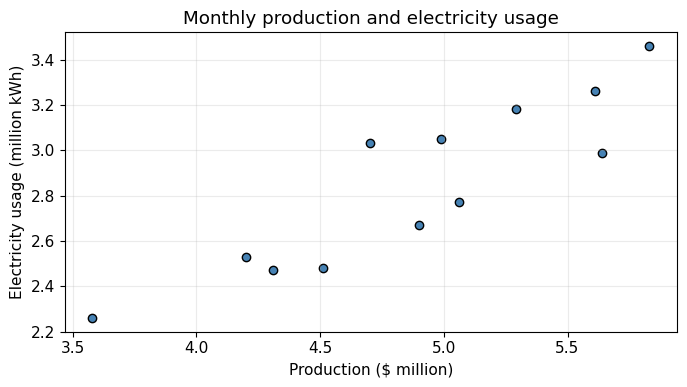

In [23]:
plt.scatter(X[:, 0], y, color="steelblue", edgecolor="black")
plt.xlabel("Production ($ million)")
plt.ylabel("Electricity usage (million kWh)")
plt.title("Monthly production and electricity usage")
plt.tight_layout()
plt.show()

### 13. Compare the marginal histograms

Histograms show the observed frequency of values in each bin. 

Use only the two original numeric variables, and interpret the shapes cautiously because the sample is small.


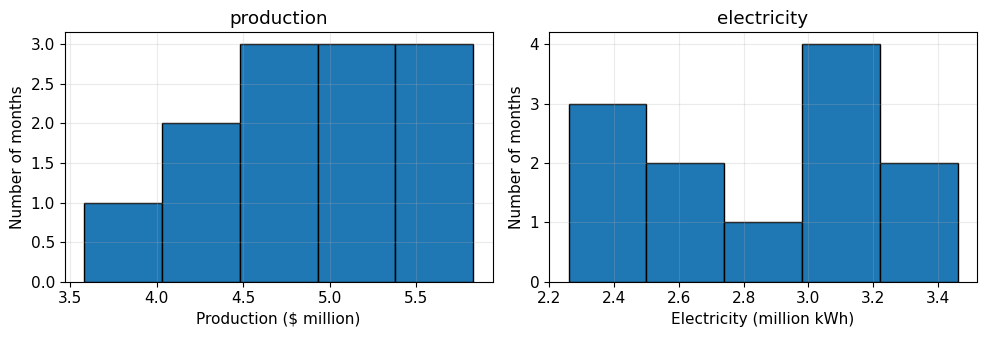

In [24]:
axes = df[["production", "electricity"]].hist(bins=5, figsize=(10, 3.5), edgecolor="black")
axes[0, 0].set_xlabel("Production ($ million)")
axes[0, 1].set_xlabel("Electricity (million kWh)")
for ax in axes.ravel():
    ax.set_ylabel("Number of months")
plt.tight_layout()
plt.show()

## Ordinary least squares by hand

For production $x$ and electricity usage $y$, the fitted line is
$\hat y=b_0+b_1x$. 

Ordinary least squares minimizes
$\sum_{i=1}^{n}(y_i-\hat y_i)^2$. 

The coefficients are

$$b_1=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sum_i(x_i-\bar x)^2}
=\frac{n\sum_i x_i y_i-(\sum_i x_i)(\sum_i y_i)}
{n\sum_i x_i^2-(\sum_i x_i)^2},$$

$$b_0=\bar y-b_1\bar x.$$

The following calculation uses all observations to explain the relationship.
A separate chronological holdout evaluation appears later.


### 14. Build the calculation table

Keep the original `df` intact and create a separate table containing x, y, their squares, and their product. 

These extra columns help derive the coefficients; they are not additional model features.


In [25]:
calculation_df = pd.DataFrame({
    "Production": X[:, 0], "Electricity": y,
    "x^2": X[:, 0] ** 2, "y^2": y ** 2, "x*y": X[:, 0] * y
})
display(calculation_df)

,Production,Electricity,x^2,y^2,x*y
0,4.51,2.48,20.3401,6.1504,11.1848
1,3.58,2.26,12.8164,5.1076,8.0908
2,4.31,2.47,18.5761,6.1009,10.6457
3,5.06,2.77,25.6036,7.6729,14.0162
4,5.64,2.99,31.8096,8.9401,16.8636
5,4.99,3.05,24.9001,9.3025,15.2195
6,5.29,3.18,27.9841,10.1124,16.8222
7,5.83,3.46,33.9889,11.9716,20.1718
8,4.70,3.03,22.0900,9.1809,14.2410
9,5.61,3.26,31.4721,10.6276,18.2886


### 15. Sum the calculation columns

The column totals provide the sums used in the expanded slope formula. 

Summing a DataFrame defaults to summing each column.


In [26]:
column_sums = calculation_df.sum()
display(column_sums.to_frame("Sum"))

,Sum
Production,58.6200
Electricity,34.1500
x^2,291.2310
y^2,98.6967
x*y,169.2532


### 16. Calculate the slope and intercept manually

Use the centered form of the formula, which avoids subtracting large, similar totals. 

A zero denominator would mean production is constant, in which case the slope is not identifiable.


In [27]:
x = X[:, 0]
x_centered = x - x.mean()
y_centered = y - y.mean()
denominator = np.dot(x_centered, x_centered)
if denominator <= 0:
    raise ValueError("Cannot estimate a slope from constant production.")
manual_slope = np.dot(x_centered, y_centered) / denominator
manual_intercept = y.mean() - manual_slope * x.mean()
print(f"Manual slope: {manual_slope:.6f}")
print(f"Manual intercept: {manual_intercept:.6f}")

Manual slope: 0.498830
Manual intercept: 0.409048


### 17. Fit the full-data explanatory model

`LinearRegression` estimates the same least-squares line with an intercept. 

This model uses every observed month; it is not a training/test split. Check that its coefficients agree with the manual calculation.


In [28]:
regressor = LinearRegression()
regressor.fit(X, y)
np.testing.assert_allclose(regressor.coef_[0], manual_slope, rtol=1e-10, atol=1e-12)
np.testing.assert_allclose(regressor.intercept_, manual_intercept, rtol=1e-10, atol=1e-12)
print("Manual and scikit-learn coefficients agree.")

Manual and scikit-learn coefficients agree.


### 18. Calculate fitted values

Predict electricity for the same production values used to fit the model. 

These are in-sample fitted values, not test predictions. Their errors describe fit to the observed data.


In [29]:
y_fitted = regressor.predict(X)
display(pd.DataFrame({"Month": df["month"], "Fitted electricity": y_fitted}))

,Month,Fitted electricity
0,January,2.658772
1,February,2.194860
2,March,2.559006
3,April,2.933129
4,May,3.222450
5,June,2.898210
6,July,3.047860
7,August,3.317228
8,September,2.753550
9,October,3.207485


### 19. Draw the fitted line

Plot the observed points and evaluate the fitted line on an ordered grid. 

Drawing a line directly through unsorted monthly production values can make the plot harder to interpret.


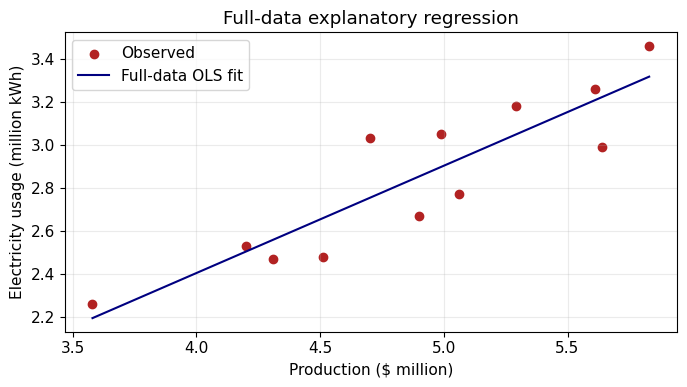

In [30]:
X_grid = np.linspace(x.min(), x.max(), 200).reshape(-1, 1)
plt.scatter(x, y, color="firebrick", label="Observed")
plt.plot(X_grid[:, 0], regressor.predict(X_grid), color="navy", label="Full-data OLS fit")
plt.xlabel("Production ($ million)")
plt.ylabel("Electricity usage (million kWh)")
plt.title("Full-data explanatory regression")
plt.legend()
plt.tight_layout()
plt.show()

### 20. Predict electricity for new production values

Retain the original examples of $5.5 million and $8.0 million production. 

Label each as interpolation or extrapolation relative to the observed range. 

The 8.0 example lies outside the original data range and is especially uncertain. 

These are point predictions, without prediction intervals.


In [31]:
new_X = np.array([[5.5], [8.0]])
new_predictions = regressor.predict(new_X)
new_results = pd.DataFrame({
    "Production ($ million)": new_X[:, 0],
    "Predicted electricity (million kWh)": new_predictions,
    "Scope": np.where((new_X[:, 0] >= x.min()) & (new_X[:, 0] <= x.max()),
                      "Interpolation", "Extrapolation")
})
display(new_results)
print(f"Observed production range: {x.min():.2f} to {x.max():.2f} ($ million)")

,Production ($ million),Predicted electricity (million kWh),Scope
0,5.5,3.152614,Interpolation
1,8.0,4.399689,Extrapolation


Observed production range: 3.58 to 5.83 ($ million)


### 21. Interpret the intercept

The intercept is the fitted electricity usage at zero production. 

Zero lies outside the original observed range, so this value should not be presented as a reliable estimate of the factory’s actual idle electricity consumption.


In [32]:
print(f"Intercept: {regressor.intercept_:.6f} million kWh at zero production.")

Intercept: 0.409048 million kWh at zero production.


### 22. Interpret the slope and display the equation

The slope is the fitted change in electricity usage, in millions of kWh, associated with a $1 million increase in production value. 

It describes association and does not establish a causal effect.


In [33]:
print(f"Slope: {regressor.coef_[0]:.6f} million kWh per $ million of production.")
print(f"Fitted equation: electricity = {regressor.intercept_:.6f} + {regressor.coef_[0]:.6f} × production")

Slope: 0.498830 million kWh per $ million of production.
Fitted equation: electricity = 0.409048 + 0.498830 × production


### 23. Compare actual and fitted values

A residual is the actual response minus the fitted response. 

Positive residuals mean the model underestimates electricity usage; negative residuals mean it overestimates usage. 

Keep month labels so errors can be traced back to observations.


In [34]:
residuals = y - y_fitted
result = pd.DataFrame({"Month": df["month"], "Production": x,
                       "Actual": y, "Fitted": y_fitted, "Residual": residuals})
display(result)

,Month,Production,Actual,Fitted,Residual
0,January,4.51,2.48,2.658772,-0.178772
1,February,3.58,2.26,2.194860,0.065140
2,March,4.31,2.47,2.559006,-0.089006
3,April,5.06,2.77,2.933129,-0.163129
4,May,5.64,2.99,3.222450,-0.232450
5,June,4.99,3.05,2.898210,0.151790
6,July,5.29,3.18,3.047860,0.132140
7,August,5.83,3.46,3.317228,0.142772
8,September,4.70,3.03,2.753550,0.276450
9,October,5.61,3.26,3.207485,0.052515


### 24. Check the residual sum

For least squares with an intercept, full-data residuals sum to approximately zero, up to floating-point rounding. 

This is a property of the fitting method and does not mean prediction errors are small. 

Absolute and squared errors do not cancel.


In [35]:
print(f"Residual sum: {residuals.sum():.12f}")
print(f"Sum of absolute residuals: {np.abs(residuals).sum():.6f}")
print(f"Residual sum of squares: {np.square(residuals).sum():.6f}")
np.testing.assert_allclose(residuals.sum(), 0.0, atol=1e-10)

Residual sum: -0.000000000000
Sum of absolute residuals: 1.693345
Residual sum of squares: 0.299110


### 25. Compare actual and fitted usage by month

Display both series in observation order to show which months are overestimated or underestimated. 

The vertical separation between the series is the residual.


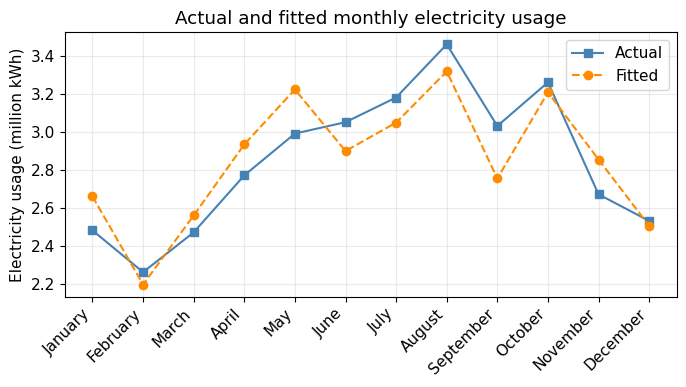

In [36]:
positions = np.arange(len(df))
plt.plot(positions, y, "s-", label="Actual", color="steelblue")
plt.plot(positions, y_fitted, "o--", label="Fitted", color="darkorange")
plt.xticks(positions, df["month"], rotation=45, ha="right")
plt.ylabel("Electricity usage (million kWh)")
plt.title("Actual and fitted monthly electricity usage")
plt.legend()
plt.tight_layout()
plt.show()

## Evaluate the full-data fit

For residuals $e_i=y_i-\hat y_i$:

$$\mathrm{MAE}=\frac{1}{n}\sum_i|e_i|,$$

$$\mathrm{MSE}=\frac{1}{n}\sum_i e_i^2,$$

$$\mathrm{RMSE}=\sqrt{\mathrm{MSE}},$$

$$R^2=1-\frac{\sum_i e_i^2}{\sum_i(y_i-\bar y)^2}.$$

MAE and RMSE are in millions of kWh; MSE is in squared millions of kWh.

These are **in-sample** metrics and may overstate performance on unseen months.

MSE here divides by $n$; it is not the regression noise-variance estimate,
which would divide the residual sum of squares by $n-2$ in this model.

### 26. Compute and interpret R²

$R^2$ compares the squared residual error with the observed variation around the response mean. 

Report the computed value dynamically instead of hard-coding 0.80. 

An explained fraction of sample variation is not evidence that production causes that fraction of electricity consumption.


In [37]:
fit_r2 = r2_score(y, y_fitted)
print(f"In-sample R^2: {fit_r2:.6f}")
print(f"The fitted line accounts for {100 * fit_r2:.2f}% of the observed sample variation in electricity usage.")

In-sample R^2: 0.802109
The fitted line accounts for 80.21% of the observed sample variation in electricity usage.


### 27. Compute mean squared error

MSE averages the squared residuals and penalizes large errors more strongly. 

Its squared units make it less directly interpretable than RMSE.


In [38]:
fit_mse = mean_squared_error(y, y_fitted)
print(f"In-sample MSE: {fit_mse:.6f} (million kWh)²")

In-sample MSE: 0.024926 (million kWh)²


### 28. Compute root mean squared error

Taking the square root of MSE returns the error to the original electricity units. 

RMSE remains sensitive to large residuals.

In [39]:
fit_rmse = np.sqrt(fit_mse)
print(f"In-sample RMSE: {fit_rmse:.6f} million kWh")

In-sample RMSE: 0.157879 million kWh


### 29. Compute mean absolute error

MAE is the average magnitude of residuals. It uses the same units as electricity usage and is less sensitive to large residuals than RMSE.


In [40]:
fit_mae = mean_absolute_error(y, y_fitted)
print(f"In-sample MAE: {fit_mae:.6f} million kWh")

In-sample MAE: 0.141112 million kWh


### 30. Calculate Pearson correlation

Calculate correlation only for the original production and electricity variables. Correlations involving x², y², and xy from the manual calculation table would be mechanically related and could obscure the question. 

For single-predictor ordinary least squares with an intercept, in-sample R² equals Pearson r squared.


In [41]:
correlation = df[["production", "electricity"]].corr(method="pearson")
pearson_r = correlation.loc["production", "electricity"]
display(correlation)
print(f"Pearson r: {pearson_r:.6f}; r²: {pearson_r ** 2:.6f}")
print("The sign indicates the direction of the linear association; values near ±1 indicate a strong linear association.")
np.testing.assert_allclose(fit_r2, pearson_r ** 2, rtol=1e-10, atol=1e-12)

,production,electricity
production,1.000000,0.895606
electricity,0.895606,1.000000


Pearson r: 0.895606; r²: 0.802109
The sign indicates the direction of the linear association; values near ±1 indicate a strong linear association.


### 31. Plot the correlation heatmap

Use a diverging color scale from −1 to +1, centered at zero. 

The original notebook incorrectly set both limits to −1. 

Annotate the cells to show the exact correlation values.


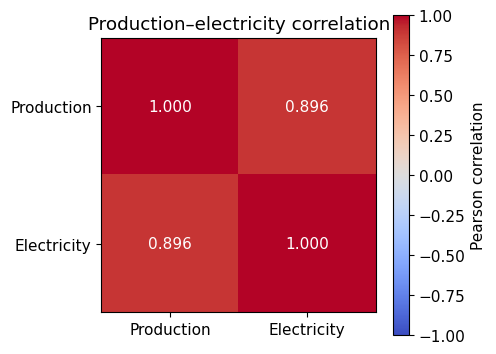

In [42]:
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(correlation.to_numpy(), cmap="coolwarm", vmin=-1, vmax=1)
labels = ["Production", "Electricity"]
ax.set_xticks([0, 1], labels=labels)
ax.set_yticks([0, 1], labels=labels)
ax.grid(False)
for row in range(2):
    for col in range(2):
        ax.text(col, row, f"{correlation.iloc[row, col]:.3f}",
                ha="center", va="center", color="white")
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Production–electricity correlation")
fig.tight_layout()
plt.show()

### 32. Inspect residual diagnostics

Residuals versus fitted values can reveal curvature or changing spread; residuals in month order may reveal time structure. 

A normal Q–Q plot compares residual quantiles with a normal distribution. 

Normality is relevant to conventional small-sample inference, not a prerequisite for calculating the OLS coefficients. 

With 12 observations, these plots cannot confirm the assumptions.


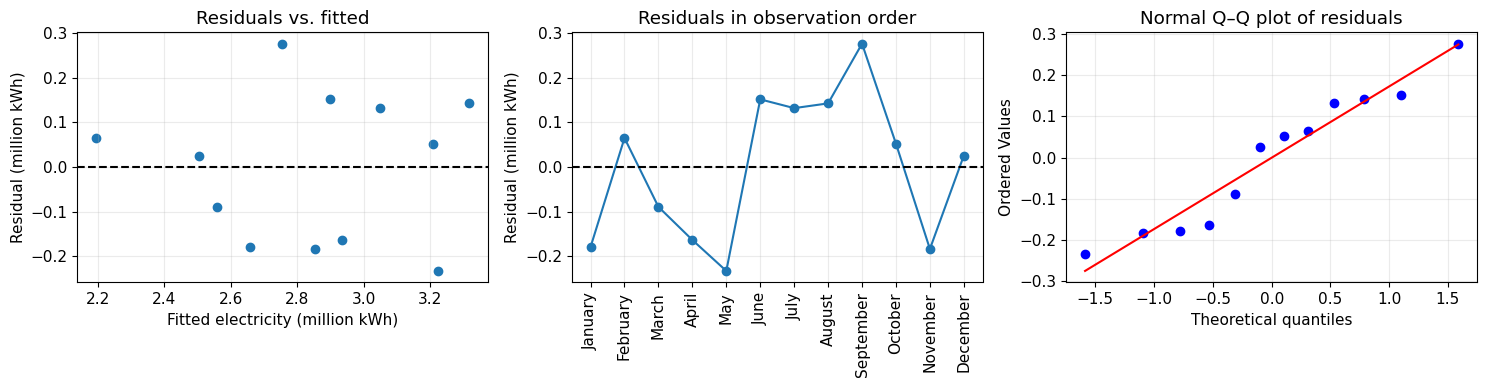

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(y_fitted, residuals)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(xlabel="Fitted electricity (million kWh)",
            ylabel="Residual (million kWh)", title="Residuals vs. fitted")
axes[1].plot(np.arange(len(df)), residuals, "o-")
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xticks(np.arange(len(df)), labels=df["month"], rotation=90)
axes[1].set(ylabel="Residual (million kWh)", title="Residuals in observation order")
stats.probplot(residuals, dist="norm", plot=axes[2])
axes[2].set_title("Normal Q–Q plot of residuals")
fig.tight_layout()
plt.show()

## Check predictions on held-out months

The full-data model above describes the available sample. To illustrate evaluation
on unseen observations, the next steps fit a **separate model** to the earlier
months and hold out the last three months. For the original data this means
January–September for training and October–December for testing.

The rows must be in chronological order. With an external CSV, confirm this order
and the units before running; alphabetical sorting of month names is not chronological.
This evaluates electricity predictions **given the held-out production values**;
it does not forecast production. There are only three test observations, so the
test metrics are unstable and do not establish reliable future performance.
The full-data fit above is not used to train or select the holdout model.


### 33. Split observations chronologically

Keep the final three rows for testing, using at least three earlier rows for training. This respects the temporal order rather than randomly mixing months. If production is constant in the training period, its slope cannot be identified.


In [44]:
TEST_MONTHS = 3
split_index = len(df) - TEST_MONTHS
if split_index < 3:
    raise ValueError("The holdout demonstration needs at least six chronological observations.")
X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]
if np.unique(X_train[:, 0]).size < 2:
    raise ValueError("Training production must vary to estimate the slope.")
print("Training months:", ", ".join(df["month"].iloc[:split_index]))
print("Test months:", ", ".join(df["month"].iloc[split_index:]))


Training months: January, February, March, April, May, June, July, August, September
Test months: October, November, December


### 34. Fit the training-only model and a baseline

Train a new regression model using only the training rows. A simple baseline predicts the training mean electricity usage for every test month. Neither method uses test electricity values during fitting.


In [45]:
holdout_regressor = LinearRegression().fit(X_train, y_train)
y_test_pred = holdout_regressor.predict(X_test)
y_baseline_pred = np.full(y_test.shape, y_train.mean(), dtype=float)
holdout_results = pd.DataFrame({
    "Month": df["month"].iloc[split_index:].to_numpy(),
    "Production": X_test[:, 0], "Actual electricity": y_test,
    "Regression prediction": y_test_pred,
    "Training-mean baseline": y_baseline_pred,
    "Regression residual": y_test - y_test_pred
})
display(holdout_results)


,Month,Production,Actual electricity,Regression prediction,Training-mean baseline,Regression residual
0,October,5.61,3.26,3.215945,2.854444,0.044055
1,November,4.90,2.67,2.864883,2.854444,-0.194883
2,December,4.20,2.53,2.518765,2.854444,0.011235


### 35. Compare holdout errors with the baseline

Report MAE, MSE, RMSE, and R² on the same test observations for both methods. A negative test R² is possible: it means squared error exceeds that of predicting the test-set mean, which is a metric reference rather than the training-mean baseline. R² is undefined when test responses are constant, so report NaN in that case.


In [46]:
def evaluate(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        "MAE (million kWh)": mean_absolute_error(actual, predicted),
        "MSE ((million kWh)²)": mse,
        "RMSE (million kWh)": np.sqrt(mse),
        "R²": r2_score(actual, predicted) if np.unique(actual).size > 1 else np.nan
    }

holdout_metrics = pd.DataFrame({
    "Regression": evaluate(y_test, y_test_pred),
    "Training-mean baseline": evaluate(y_test, y_baseline_pred)
}).T
display(holdout_metrics)
print("Lower MAE, MSE, and RMSE indicate smaller errors; higher R² indicates a better fit on this test set.")
print("Only three test months are available; interpret these estimates cautiously.")


,MAE (million kWh),MSE ((million kWh)²),RMSE (million kWh),R²
Regression,0.083391,0.013349,0.115537,0.866601
Training-mean baseline,0.304815,0.101253,0.318203,-0.011856


Lower MAE, MSE, and RMSE indicate smaller errors; higher R² indicates a better fit on this test set.
Only three test months are available; interpret these estimates cautiously.


## Interpretation and limitations

- In the original 12-month dataset, the full-data line is approximately
  **electricity = 0.409048 + 0.498830 × production**. Its in-sample
  **R² ≈ 0.8021** and **Pearson r ≈ 0.8956** indicate a strong positive linear
  association in this sample. These reference numbers apply to the embedded
  dataset; computed outputs should be used if a different CSV is supplied.
- The explanatory model and the training-only holdout model have different
  purposes and generally different coefficients. In-sample errors are not
  estimates of future predictive accuracy.
- Production value is not a direct count of cars. Weather, product mix,
  operating hours, equipment, and seasonality could also affect electricity.
  The model does not control for these factors and supports no causal claim.
- Twelve months from one year provide limited evidence, especially for
  seasonal patterns and independent errors. More data and rolling or expanding
  chronological validation would be needed for a dependable forecasting study.
- The prediction at production 8.0 is an extrapolation. The intercept is also
  outside the observed production range. Neither should be interpreted as a
  well-supported physical operating estimate.
- No confidence or prediction intervals are supplied. Reliable intervals would
  require justified assumptions about the errors and temporal dependence.
